# 03 — Spatial structure

Fitting the model.

LunaRec decides which patch to image next. To do that it has to hold a belief
about patches it has *not* imaged — otherwise there is nothing to be uncertain
about and nothing for an acquisition to resolve. That belief is a Gaussian
process over each attribute, and the GP is defined entirely by its covariance:
how strongly two patches are expected to agree as a function of how far apart
they are.

So the covariance is not a tuning detail. It is the model. Three numbers
describe it:

| | meaning | consequence if wrong |
|---|---|---|
| **range** | separation beyond which patches are uncorrelated | sets how far one observation informs its neighbours |
| **sill** | total variance of the field | scales everything |
| **nugget** | variance left at zero separation | how much is unlearnable from neighbours |

The criterion propagates information through exactly this covariance, so it is
the policy most exposed to getting it wrong.

### Why this notebook exists

An earlier revision of `evaluate.py` hardcoded a range of 1100 m and a nugget
of 0.10, carried from a single early fit. Measured against the scenes, those
were wrong by roughly **3× in range and 5× in nugget**. Every result produced
under them came from a GP that believed observations stop informing neighbours
at about a kilometre when they actually carry to three, and that a tenth of the
signal was noise when nearly half is.

This notebook replaces those assumptions with measurements, per scene and per
attribute, by two independent methods:

1. **Variogram fitting** — bin the semivariance by separation and fit the
   spherical model by weighted least squares. Interpretable: you can look at
   the binned points and see whether the model describes them.
2. **Marginal likelihood** — optimise the GP hyperparameters directly by
   maximising the log marginal likelihood of the observed data. More
   principled, and it is a training procedure in the ordinary sense: a loss, an
   optimiser, learned parameters, a convergence curve.

Keeping both is deliberate. Two independent estimates agreeing is a stronger
result than either alone, and disagreement would be informative in itself.

### What to expect

The hazard nugget comes out near **0.45**. Read on its own that looks like
noise, which would be bad news. Read against notebook 02's repeatability — 78%
to 91% of the label's variance is reproducible ground — it says something more
useful: roughly half the variance is **real structure finer than the 200 m
patch grid**, not measurement error.

That is the quantitative reason hazard cannot be extrapolated from neighbouring
patches, and therefore the reason verification imaging is necessary at all. It
is the strongest single argument for the project's premise, and it is measured
rather than assumed.

### A note on method

This notebook imports `empirical_variogram`, `fit` and `spherical_model` from
`src/fit_variogram.py` rather than reimplementing them. What is validated here
is the code that actually runs in `evaluate.py`; a notebook copy would be free
to drift from the pipeline, and the figures would then describe something the
pipeline does not do.

**Cell 1** - setup

In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from lunarec_style import *                      # noqa: F403
# Import the PIPELINE implementation rather than reimplementing it here, so
# this notebook validates the code that actually runs in evaluate.py. A
# notebook copy would be free to drift from it, and then the figures would
# describe something the pipeline does not do.
from fit_variogram import empirical_variogram, fit as fit_spherical, spherical_model

PATCHES = ROOT / "data" / "patches" / "current"
out = ROOT / "results" / "figures"
out.mkdir(parents=True, exist_ok=True)

SCENES = {
    "0858":  ("B", "patches_0858_rt.csv"),
    "1647a": ("B", "patches_1647a_rt.csv"),
    "C1":    ("C", "patches_C1.csv"),
    "C2":    ("C", "patches_C2.csv"),
}
# (column, label, stakeholder) -- the three attributes the recommender ranks on.
ATTRS = [
    ("shadow_local", "hazard",       "safety"),
    ("dn_mean",      "illumination", "operations"),
    ("dn_std",       "texture",      "science"),
]
SUBSAMPLE = 1400     # pair count is O(n^2); 1400 gives ~1M pairs per fit

scenes = {lab: pd.read_csv(PATCHES / f).dropna(
              subset=[c for c, _, _ in ATTRS] + ["patch_x", "patch_y"])
          for lab, (_, f) in SCENES.items()}

print(f"{len(scenes)} scenes loaded")
for lab, d in scenes.items():
    print(f"  {lab:<6} {len(d):>5} patches")
print(f"\nsubsample for variograms: {SUBSAMPLE} "
      f"(~{SUBSAMPLE*(SUBSAMPLE-1)//2:,} pairs per fit)")
print(f"imported from src/fit_variogram.py: "
      f"{', '.join(['empirical_variogram', 'fit', 'spherical_model'])}")

4 scenes loaded
  0858    2010 patches
  1647a   2008 patches
  C1      1875 patches
  C2      1930 patches

subsample for variograms: 1400 (~979,300 pairs per fit)
imported from src/fit_variogram.py: empirical_variogram, fit, spherical_model


**Cell 2** — empirical variograms and the spherical fit, all twelve:

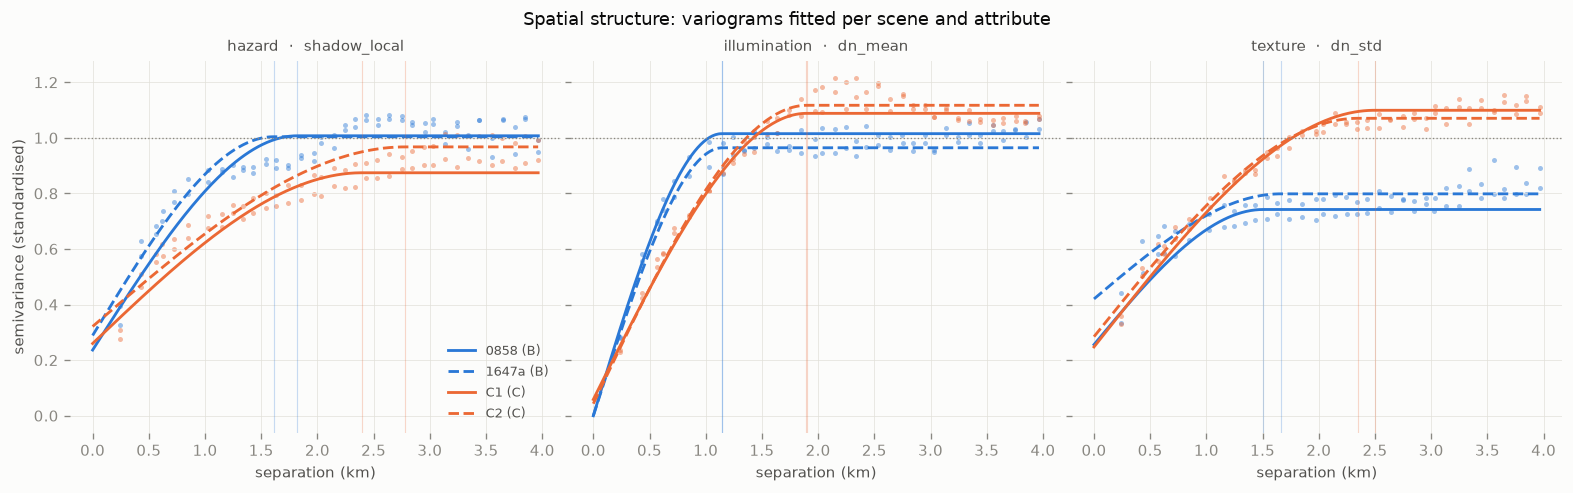

            fit_r2                      nugget                        range_m                       
attribute   hazard illumination texture hazard illumination texture    hazard illumination   texture
block scene                                                                                         
B     0858   0.852        0.967   0.846  0.235        0.000   0.345  1818.757     1143.466  1503.520
      1647a  0.835        0.946   0.742  0.288        0.000   0.527  1610.797     1148.057  1660.092
C     C1     0.908        0.972   0.984  0.297        0.054   0.225  2394.032     1895.547  2495.827
      C2     0.930        0.963   0.972  0.332        0.039   0.266  2781.580     1901.735  2346.922


In [4]:
# Twelve fits: four scenes x three attributes.
#
# Each attribute is standardised first, so the sill lands near 1 and the
# nugget reads directly as the FRACTION of variance that is uncorrelated at
# the patch grid's own spacing. That is the number evaluate.py consumes.
#
# Weighted least squares on the binned semivariance, weights = pair counts, so
# the well-populated short lags -- which determine the nugget and the range --
# are not outvoted by the many noisy long-lag bins.
BLOCK_COLOR = {"B": "#2a78d6", "C": "#eb6834"}
SCENE_STYLE = {"0858": "-", "1647a": "--", "C1": "-", "C2": "--"}

vg = {}      # (scene, attr) -> (centres, gamma, counts, nugget, sill, range, r2)
rows = []
for lab, d in scenes.items():
    block = SCENES[lab][0]
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, holder in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        c, g, k = empirical_variogram(xy, z)
        (nug, sill, rng_), r2 = fit_spherical(c, g, k)
        vg[(lab, col)] = (c, g, k, nug, sill, rng_, r2)
        rows.append({"scene": lab, "block": block, "attribute": name,
                     "range_m": rng_, "nugget": nug / sill, "sill": sill,
                     "fit_r2": r2})

fits = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0), sharey=True,
                         constrained_layout=True)
for ax, (col, name, holder) in zip(axes, ATTRS):
    for lab in scenes:
        block = SCENES[lab][0]
        c, g, k, nug, sill, rng_, r2 = vg[(lab, col)]
        ax.scatter(c / 1000, g, s=9, color=BLOCK_COLOR[block], alpha=0.45,
                   linewidths=0)
        hh = np.linspace(0, c.max(), 300)
        ax.plot(hh / 1000, spherical_model(hh, nug, sill, rng_),
                color=BLOCK_COLOR[block], linestyle=SCENE_STYLE[lab],
                linewidth=1.7, label=f"{lab} ({block})")
        # The fitted range, marked where the model reaches its sill.
        ax.axvline(rng_ / 1000, color=BLOCK_COLOR[block], linewidth=0.7,
                   alpha=0.25)
    ax.axhline(1.0, color=MUTED, linewidth=0.8, linestyle=":")
    ax.set_title(f"{name}  ·  {col}", color=INK2, fontsize=9)
    ax.set_xlabel("separation (km)")
    bare(ax)
axes[0].set_ylabel("semivariance (standardised)")
axes[0].legend(frameon=False, fontsize=8, labelcolor=INK2, loc="lower right")
fig.suptitle("Spatial structure: variograms fitted per scene and attribute",
             color=INK, fontsize=11)
fig.savefig(out / "03_variograms.png", bbox_inches="tight")
plt.show()

print(fits.pivot_table(index=["block", "scene"], columns="attribute",
                       values=["range_m", "nugget", "fit_r2"]).round(3)
      .to_string())

**Cell 3** — is the 4 km window long enough?

In [20]:
# The sill should land at 1.0: the attributes are standardised, so total
# variance is 1 by construction. Several fits saturate well below that, which
# means correlated structure continues past the 4 km window fit_variogram2.py
# examines.
#
# That matters beyond tidiness. The nugget is reported as nugget/sill, so a
# sill fitted at 0.75 inflates the reported nugget fraction by a third against
# the true share of variance. evaluate.py consumes that ratio directly.
#
# The scenes are ~29 km across the diagonal, so lags to 8 km are well sampled.
LAGS = [4000.0, 6000.0, 8000.0]

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        for L in LAGS:
            c, g, k = empirical_variogram(xy, z, max_lag=L)
            (nug, sill, rng_), r2 = fit_spherical(c, g, k)
            rows.append({"scene": lab, "attribute": name, "max_lag_km": L / 1000,
                         "sill": sill, "range_m": rng_,
                         "nugget/sill": nug / sill, "nugget/total": nug,
                         "fit_r2": r2})
lagtest = pd.DataFrame(rows)

print("sill by fit window (should be ~1.0 on standardised data)")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="sill").round(3).to_string())
print("\nfitted range (m) by fit window")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="range_m").round(0).to_string())
print("\nnugget as a fraction of TOTAL variance (not of the fitted sill)")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="nugget/total").round(3).to_string())

worst = lagtest[lagtest.max_lag_km == 4.0].nsmallest(3, "sill")
print(f"\nfurthest from a unit sill at 4 km: "
      f"{', '.join(f'{r.scene}/{r.attribute} {r.sill:.2f}' for r in worst.itertuples())}")

sill by fit window (should be ~1.0 on standardised data)
max_lag_km            4.0    6.0    8.0
scene attribute                        
0858  hazard        1.037  1.028  1.019
      illumination  1.016  1.052  1.060
      texture       0.750  0.902  1.002
1647a hazard        1.048  1.060  1.033
      illumination  0.968  0.967  0.933
      texture       0.815  0.862  0.872
C1    hazard        0.905  1.015  1.148
      illumination  1.095  1.121  1.169
      texture       1.107  1.146  1.242
C2    hazard        0.998  1.033  1.093
      illumination  1.124  1.130  1.172
      texture       1.077  1.131  1.334

fitted range (m) by fit window
max_lag_km             4.0     6.0     8.0
scene attribute                           
0858  hazard        2535.0  2462.0  2413.0
      illumination  1117.0  1211.0  1250.0
      texture       1850.0  5940.0  7909.0
1647a hazard        2750.0  2875.0  2615.0
      illumination  1221.0  1226.0  1072.0
      texture       2523.0  4527.0  4814.0
C1    h

**Is the along-strip structure instrumental?**

In [11]:
# Terrain genuinely varies along a strip, so a gradient in the attribute alone
# proves nothing. The discriminator is the DIFFERENCE between two scenes
# covering the same ground: terrain cancels, and whatever gradient survives
# belongs to the acquisition rather than the Moon.
#
# A pushbroom reads a line at once across-track and accumulates down-track, so
# radiometric drift, gain change or slow illumination change during the pass
# should appear as an along-strip gradient in the difference -- and not an
# across-strip one, which is the control.
GRID_M = 200.0

def project(xy, axis_deg):
    """Along- and across-strip coordinates, metres from the centroid."""
    a = np.radians(axis_deg)
    c = xy - xy.mean(0)
    along = c[:, 0] * np.cos(a) + c[:, 1] * np.sin(a)
    across = -c[:, 0] * np.sin(a) + c[:, 1] * np.cos(a)
    return along, across

def lin_r2(x, y):
    """R^2 of a straight-line fit, plus the slope per km."""
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 50 or x.std() == 0 or y.std() == 0:
        return np.nan, np.nan
    b, a = np.polyfit(x, y, 1)
    pred = a + b * x
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return float(r2), float(b * 1000.0)        # slope per km

# --- context: how much does each attribute itself trend? -----------------
rows = []
for lab, d in scenes.items():
    xy = d[["patch_x", "patch_y"]].values
    s, t = project(xy, strip_axis_deg(xy))
    for col, name, _ in ATTRS:
        v = d[col].values.astype(float)
        r2s, _ = lin_r2(s, v)
        r2t, _ = lin_r2(t, v)
        rows.append({"scene": lab, "attribute": name,
                     "R2 along": r2s, "R2 across": r2t})
print("context -- gradient in the attribute itself (terrain + acquisition)")
print(pd.DataFrame(rows).pivot_table(index=["scene", "attribute"],
      values=["R2 along", "R2 across"]).round(3).to_string())

# --- the decisive test: gradient in the DIFFERENCE ------------------------
PAIRS = [("0858", "1647a"), ("C1", "C2")]
rows = []
for a, b in PAIRS:
    da, db = scenes[a].copy(), scenes[b].copy()
    for d in (da, db):
        d["gx"] = np.floor(d.patch_x / GRID_M).astype(np.int64)
        d["gy"] = np.floor(d.patch_y / GRID_M).astype(np.int64)
    m = da.merge(db, on=["gx", "gy"], suffixes=("_a", "_b"))
    xy = m[["patch_x_a", "patch_y_a"]].values
    axis = strip_axis_deg(xy)
    s, t = project(xy, axis)
    for col, name, _ in ATTRS:
        # Standardise each scene before differencing, so a pure scale change
        # between passes does not masquerade as a gradient.
        za = (m[f"{col}_a"] - m[f"{col}_a"].mean()) / m[f"{col}_a"].std()
        zb = (m[f"{col}_b"] - m[f"{col}_b"].mean()) / m[f"{col}_b"].std()
        diff = (za - zb).values
        r2s, slope_s = lin_r2(s, diff)
        r2t, slope_t = lin_r2(t, diff)
        rows.append({"pair": f"{a}-{b}", "attribute": name, "shared": len(m),
                     "R2 along": r2s, "slope along /km": slope_s,
                     "R2 across": r2t, "slope across /km": slope_t})
diffs = pd.DataFrame(rows)
print("\nDECISIVE -- gradient in the scene-to-scene DIFFERENCE")
print("(terrain cancels; what remains is the acquisition)\n")
print(diffs.set_index(["pair", "attribute"]).round(4).to_string())

print(f"\nmean R2 along  {diffs['R2 along'].mean():.4f}"
      f"     mean R2 across {diffs['R2 across'].mean():.4f}")

context -- gradient in the attribute itself (terrain + acquisition)
                    R2 across  R2 along
scene attribute                        
0858  hazard            0.016     0.014
      illumination      0.001     0.001
      texture           0.000     0.144
1647a hazard            0.000     0.034
      illumination      0.001     0.030
      texture           0.000     0.050
C1    hazard            0.001     0.024
      illumination      0.010     0.009
      texture           0.016     0.000
C2    hazard            0.007     0.010
      illumination      0.000     0.006
      texture           0.007     0.002

DECISIVE -- gradient in the scene-to-scene DIFFERENCE
(terrain cancels; what remains is the acquisition)

                         shared  R2 along  slope along /km  R2 across  slope across /km
pair       attribute                                                                   
0858-1647a hazard          1587    0.0000          -0.0002     0.0038            0.0372
 

**Cell 4** — does detrending make the ranges identifiable?

In [9]:
# A range that grows with the fit window is not a range. It is the window.
# The usual cause is a spatial trend: a trended field's variogram rises without
# bound, so a bounded model fitted to it returns roughly the window size.
#
# Removing a quadratic trend in (x, y) before computing the variogram tests
# that directly. If the ranges stabilise afterwards, the fields are stationary
# once the trend is out and the pipeline's stationary fit is a documented
# approximation. If they still grow, something else is going on -- anisotropy
# is the next suspect, since these are long thin strips and a variogram pooled
# over all directions mixes along-track with cross-track structure.
def detrend_xy(v, xs, ys):
    sx = (xs - xs.mean()) / max(xs.std(), 1.0)
    sy = (ys - ys.mean()) / max(ys.std(), 1.0)
    A = np.column_stack([np.ones_like(sx), sx, sy, sx*sx, sx*sy, sy*sy])
    coef, *_ = np.linalg.lstsq(A, v, rcond=None)
    return v - A @ coef

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    xs, ys = xy[:, 0], xy[:, 1]
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        for mode in ("raw", "detrended"):
            v = raw if mode == "raw" else detrend_xy(raw, xs, ys)
            z = (v - v.mean()) / v.std()
            for L in (4000.0, 8000.0):
                c, g, k = empirical_variogram(xy, z, max_lag=L)
                (nug, sill, rng_), r2 = fit_spherical(c, g, k)
                rows.append({"scene": lab, "attribute": name, "mode": mode,
                             "lag_km": L / 1000, "range_m": rng_,
                             "sill": sill, "nugget": nug})
dt = pd.DataFrame(rows)

print("fitted range (m): does it stop chasing the window once detrended?")
print(dt.pivot_table(index=["scene", "attribute"], columns=["mode", "lag_km"],
                     values="range_m").round(0).to_string())

# Range drift, as a ratio. ~1 means identified; >>1 means window-dependent.
drift = (dt.pivot_table(index=["scene", "attribute"], columns=["mode", "lag_km"],
                        values="range_m"))
ratio = pd.DataFrame({
    "raw 8km/4km":       drift[("raw", 8.0)] / drift[("raw", 4.0)],
    "detrended 8km/4km": drift[("detrended", 8.0)] / drift[("detrended", 4.0)],
})
print("\nrange drift ratio (1.0 = identified, >1.5 = window-dependent)")
print(ratio.round(2).to_string())
print(f"\nmean drift   raw {ratio['raw 8km/4km'].mean():.2f}"
      f"   detrended {ratio['detrended 8km/4km'].mean():.2f}")

fitted range (m): does it stop chasing the window once detrended?
mode               detrended             raw        
lag_km                   4.0     8.0     4.0     8.0
scene attribute                                     
0858  hazard          2566.0  2445.0  2535.0  2413.0
      illumination    1088.0  1140.0  1117.0  1250.0
      texture         1403.0  1572.0  1850.0  7909.0
1647a hazard          2749.0  2567.0  2750.0  2615.0
      illumination    1067.0   957.0  1221.0  1072.0
      texture          973.0   812.0  2523.0  4814.0
C1    hazard          2873.0  7703.0  3232.0  7896.0
      illumination    2042.0  2358.0  2029.0  2409.0
      texture         2772.0  4102.0  2648.0  4474.0
C2    hazard          3566.0  4599.0  3525.0  5161.0
      illumination    1992.0  2154.0  1984.0  2156.0
      texture         2554.0  7895.0  2506.0  7895.0

range drift ratio (1.0 = identified, >1.5 = window-dependent)
                    raw 8km/4km  detrended 8km/4km
scene attribute          

**Cell 5** — directional variograms:

In [10]:
# Is cluster C's unbounded range anisotropy?
#
# These are long thin strips. A variogram pooled over all directions mixes
# along-strip structure, sampled out to ~26 km, with cross-strip structure that
# runs out at ~12 km. If the two directions have genuinely different ranges,
# the pooled fit is an average of them and will chase whatever window it is
# given. Cluster C is 2.2:1; cluster B is 1.3:1 -- which matches which one
# broke.
#
# Split the pairs by orientation relative to each strip's own principal axis
# and fit each direction separately.
def strip_axis_deg(xy):
    """Principal axis of the patch cloud, in degrees, 0-180."""
    c = xy - xy.mean(0)
    _, _, vt = np.linalg.svd(c, full_matrices=False)
    return float(np.degrees(np.arctan2(vt[0, 1], vt[0, 0])) % 180.0)

def directional_variogram(xy, z, axis_deg, tol_deg=30.0,
                          max_lag=8000.0, n_bins=36, min_pairs=40):
    dx = xy[:, 0][:, None] - xy[:, 0]
    dy = xy[:, 1][:, None] - xy[:, 1]
    iu = np.triu_indices(len(z), k=1)
    d = np.hypot(dx, dy)[iu]
    # Angle of each pair, folded to 0-180 and then to its separation from the
    # chosen axis, so a pair at 175 deg counts as 5 deg from a 0 deg axis.
    ang = (np.degrees(np.arctan2(dy, dx)) % 180.0)[iu]
    off = np.abs((ang - axis_deg + 90.0) % 180.0 - 90.0)
    g = (0.5 * (z[:, None] - z[None, :]) ** 2)[iu]

    keep = (d <= max_lag) & (off <= tol_deg)
    d, g = d[keep], g[keep]
    edges = np.linspace(0, max_lag, n_bins + 1)
    idx = np.clip(np.digitize(d, edges) - 1, 0, n_bins - 1)
    cs, gs, ks = [], [], []
    for b in range(n_bins):
        m = idx == b
        if m.sum() >= min_pairs:
            cs.append(d[m].mean()); gs.append(g[m].mean()); ks.append(int(m.sum()))
    return np.array(cs), np.array(gs), np.array(ks)

rows = []
for lab, d_ in scenes.items():
    sub = d_.sample(min(1200, len(d_)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    axis = strip_axis_deg(xy)
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        for dname, a in (("along", axis), ("across", (axis + 90.0) % 180.0)):
            for L in (4000.0, 8000.0):
                c, g, k = directional_variogram(xy, z, a, max_lag=L)
                if len(c) < 6:
                    continue
                (nug, sill, rng_), r2 = fit_spherical(c, g, k)
                rows.append({"scene": lab, "attribute": name, "dir": dname,
                             "lag_km": L / 1000, "range_m": rng_,
                             "axis_deg": axis})
an = pd.DataFrame(rows)

print("strip principal axis per scene")
for lab, d_ in scenes.items():
    xy = d_[["patch_x", "patch_y"]].values
    print(f"  {lab:<6} {strip_axis_deg(xy):6.1f} deg")

print("\nfitted range (m) by direction")
print(an.pivot_table(index=["scene", "attribute"], columns=["dir", "lag_km"],
                     values="range_m").round(0).to_string())

piv = an.pivot_table(index=["scene", "attribute"], columns="dir",
                     values="range_m", aggfunc=lambda s: s.iloc[0])
print("\nanisotropy ratio at the 4 km window (along / across)")
print((piv["along"] / piv["across"]).round(2).to_string())

strip principal axis per scene
  0858     54.0 deg
  1647a    57.6 deg
  C1       70.2 deg
  C2       71.0 deg

fitted range (m) by direction
dir                 across           along        
lag_km                 4.0     8.0     4.0     8.0
scene attribute                                   
0858  hazard        3415.0  3419.0  2029.0  2994.0
      illumination   757.0   769.0  1829.0  1970.0
      texture       1343.0  1309.0  2053.0  7885.0
1647a hazard        3405.0  3405.0  1221.0  3145.0
      illumination   830.0   837.0  1878.0  1579.0
      texture       1072.0  1061.0  3034.0  3854.0
C1    hazard        1376.0  1395.0  2967.0  7881.0
      illumination  2121.0  2165.0  2366.0  3244.0
      texture       1996.0  2003.0  3031.0  7881.0
C2    hazard        1461.0  1484.0  3445.0  4071.0
      illumination  2507.0  2544.0  1953.0  2046.0
      texture       2122.0  2153.0  2385.0  2936.0

anisotropy ratio at the 4 km window (along / across)
scene  attribute   
0858   hazard      

**Cell 6** - the training step 

In [6]:
from fit_gp import fit_gp

# The likelihood works on the full covariance matrix, so cost is O(n^3) per
# evaluation and the optimiser needs many. 500 points keeps each Cholesky to
# milliseconds, against 1400 used for the variograms where only pair distances
# matter. The earlier check confirmed both see the same shortest lag (~240 m),
# so the subsample size is not what separates the two methods.
GP_N = 500

rows, curves = [], {}
for lab, d in scenes.items():
    sub = d.sample(min(GP_N, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        rng_, nug, s2, hist = fit_gp(xy, z)
        curves[(lab, name)] = hist
        vrng, vnug = (fits.query("scene == @lab and attribute == @name")
                      [["range_m", "nugget"]].iloc[0])
        rows.append({"scene": lab, "attribute": name,
                     "range (likelihood)": rng_, "range (variogram)": vrng,
                     "nugget (likelihood)": nug, "nugget (variogram)": vnug,
                     "sigma2": s2, "iters": len(hist)})

gp = pd.DataFrame(rows)
print("two independent methods, same quantities")
print("(variogram column now uses Cressie weights)\n")
print(gp.set_index(["scene", "attribute"]).round(3).to_string())

rr = gp["range (likelihood)"] / gp["range (variogram)"]
nn = gp["nugget (likelihood)"] - gp["nugget (variogram)"]
print(f"\nrange ratio  likelihood/variogram: "
      f"median {rr.median():.2f}, range {rr.min():.2f}-{rr.max():.2f}")
print(f"nugget difference (likelihood - variogram): "
      f"median {nn.median():+.3f}, max |diff| {nn.abs().max():.3f}")
print("\nBEFORE the weighting fix: range ratio median 0.73, "
      "nugget difference median -0.186")

two independent methods, same quantities
(variogram column now uses Cressie weights)

                    range (likelihood)  range (variogram)  nugget (likelihood)  nugget (variogram)  sigma2  iters
scene attribute                                                                                                  
0858  hazard                   884.910           1818.757                0.000               0.235   1.056     27
      illumination             991.953           1143.466                0.000               0.000   0.955     32
      texture                 2614.604           1503.520                0.218               0.345   1.219     10
1647a hazard                   804.832           1610.797                0.000               0.288   1.015     30
      illumination            1032.247           1148.057                0.000               0.000   0.897     30
      texture                 1211.764           1660.092                0.173               0.527   1.079     15
C1

In [16]:
# Two questions, neither of which requires trusting the optimiser.
#
# 1. Was the comparison fair? The variograms used 1400 points and the
#    likelihood 500. At 500 points over an 18x23 km strip the mean
#    nearest-neighbour spacing is ~460 m, so pairs at the 200 m grid spacing --
#    exactly where the nugget is constrained -- are largely absent. Refit the
#    variogram on the SAME 500 points and the comparison becomes like for like.
#
# 2. Did the optimiser find the minimum? Evaluate the negative log marginal
#    likelihood on a grid of (range, nugget) and look at where the true minimum
#    sits. If it is at nugget ~0, the optimiser was right and the disagreement
#    is real. If it is near 0.45, the optimiser stalled on the saturating
#    sigmoid and its nuggets mean nothing.
from fit_gp import neg_log_marginal

TEST = ("0858", "hazard", "shadow_local")
lab, name, col = TEST
sub500 = scenes[lab].sample(500, random_state=0)
xy500 = sub500[["patch_x", "patch_y"]].values
z500 = ((sub500[col] - sub500[col].mean()) / sub500[col].std()).values

print("1. same-subsample comparison (both methods on the same 500 points)")
c, g, k = empirical_variogram(xy500, z500)
(nug5, sill5, rng5), r2_5 = fit_spherical(c, g, k)
print(f"   variogram on 500 pts : range {rng5:7.0f}  nugget {nug5/sill5:.3f}")
print(f"   variogram on 1400 pts: range "
      f"{fits.query('scene==@lab and attribute==@name').range_m.iloc[0]:7.0f}"
      f"  nugget "
      f"{fits.query('scene==@lab and attribute==@name').nugget.iloc[0]:.3f}")
print(f"   shortest lag sampled : {c.min():.0f} m  (500 pts)")

sub1400 = scenes[lab].sample(1400, random_state=0)
c14, _, _ = empirical_variogram(sub1400[["patch_x", "patch_y"]].values,
                                np.zeros(1400))
print(f"   shortest lag sampled : {c14.min():.0f} m  (1400 pts)")

print("\n2. likelihood surface -- where is the minimum, really?")
D500 = np.hypot(xy500[:, 0][:, None] - xy500[:, 0],
                xy500[:, 1][:, None] - xy500[:, 1])
RANGES = np.array([400, 700, 1000, 1500, 2000, 2600, 3200, 4000], float)
NUGGETS = np.array([0.001, 0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65])

surf = np.zeros((len(NUGGETS), len(RANGES)))
for i, nu in enumerate(NUGGETS):
    for j, rg in enumerate(RANGES):
        theta = np.array([np.log(rg), np.log(nu / (1 - nu)), 0.0])
        surf[i, j] = neg_log_marginal(theta, D500, z500)

best = np.unravel_index(np.argmin(surf), surf.shape)
print(f"   grid minimum at range {RANGES[best[1]]:.0f} m, "
      f"nugget {NUGGETS[best[0]]:.3f}   NLL {surf[best]:.1f}")
print(f"   optimiser returned    range "
      f"{gp.query('scene==@lab and attribute==@name')['range (likelihood)'].iloc[0]:.0f} m, "
      f"nugget "
      f"{gp.query('scene==@lab and attribute==@name')['nugget (likelihood)'].iloc[0]:.3f}")

print("\n   NLL surface (rows = nugget, cols = range in m)")
print("        " + "".join(f"{r:>9.0f}" for r in RANGES))
for i, nu in enumerate(NUGGETS):
    marker = " *" if i == best[0] else "  "
    print(f"  {nu:5.3f}{marker}" + "".join(f"{v:9.1f}" for v in surf[i]))

1. same-subsample comparison (both methods on the same 500 points)
   variogram on 500 pts : range    2764  nugget 0.476
   variogram on 1400 pts: range    2535  nugget 0.436
   shortest lag sampled : 240 m  (500 pts)
   shortest lag sampled : 241 m  (1400 pts)

2. likelihood surface -- where is the minimum, really?
   grid minimum at range 1000 m, nugget 0.050   NLL 611.9
   optimiser returned    range 885 m, nugget 0.000

   NLL surface (rows = nugget, cols = range in m)
              400      700     1000     1500     2000     2600     3200     4000
  0.001      665.4    616.9    614.6    661.7    735.3    837.1    953.4   1124.5
  0.050 *    667.4    620.1    611.9    640.0    684.0    736.7    795.1    874.8
  0.150      671.4    627.5    613.5    623.1    643.4    663.2    687.5    720.9
  0.250      675.4    635.4    619.3    620.9    632.0    641.0    654.4    673.8
  0.350      679.5    643.5    627.1    624.8    631.2    635.7    644.2    657.3
  0.450      683.6    651.9    

In [17]:
# The weighting in fit_variogram.fit() is backwards. sigma = 1/sqrt(counts)
# weights each bin by sqrt(pair count), and pair counts GROW with lag, so the
# fit is dominated by long lags -- then inflates the nugget to patch the
# short-lag misfit it created. Cressie's weights, N(h)/gamma(h)^2, upweight
# short lags because gamma is small there.
from scipy.optimize import curve_fit

def fit_cressie(centres, gamma, counts):
    s0 = float(np.median(gamma[-5:]))
    g = np.maximum(gamma, 1e-6)
    sigma = g / np.sqrt(counts)          # residual weight = sqrt(N)/gamma
    popt, _ = curve_fit(spherical_model, centres, gamma,
                        p0=[0.1 * s0, s0, 1000.0], sigma=sigma,
                        bounds=([0.0, 1e-6, 50.0],
                                [s0 * 1.5, s0 * 3, float(centres.max())]),
                        maxfev=20000)
    return popt

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        c, g, k = empirical_variogram(xy, z)
        nugC, sillC, rngC = fit_cressie(c, g, k)
        vr = fits.query("scene == @lab and attribute == @name").iloc[0]
        gl = gp.query("scene == @lab and attribute == @name").iloc[0]
        rows.append({
            "scene": lab, "attribute": name,
            "range: current": vr.range_m, "range: Cressie": rngC,
            "range: likelihood": gl["range (likelihood)"],
            "nugget: current": vr.nugget, "nugget: Cressie": nugC / sillC,
            "nugget: likelihood": gl["nugget (likelihood)"],
            "fit err at shortest lag":
                abs(spherical_model(np.array([c[0]]), nugC, sillC, rngC)[0] - g[0]),
        })
print(pd.DataFrame(rows).set_index(["scene", "attribute"]).round(3).to_string())

                    range: current  range: Cressie  range: likelihood  nugget: current  nugget: Cressie  nugget: likelihood  fit err at shortest lag
scene attribute                                                                                                                                     
0858  hazard              2534.865        1818.757            884.910            0.436            0.235               0.000                    0.063
      illumination        1116.699        1143.466            991.953            0.000            0.000               0.000                    0.035
      texture             1849.935        1503.520           2614.604            0.477            0.345               0.218                    0.039
1647a hazard              2750.139        1610.797            804.832            0.523            0.288               0.000                    0.054
      illumination        1220.796        1148.057           1032.247            0.081            0.000   

median nearest-neighbour separation: 200 m

kind                neighbour  repeat   gain
scene attribute                             
0858  hazard            0.715   0.884  0.168
      illumination      0.747   0.987  0.240
      texture           0.698   0.971  0.273
1647a hazard            0.686   0.884  0.198
      illumination      0.772   0.987  0.215
      texture           0.649   0.971  0.322
C1    hazard            0.768   0.955  0.187
      illumination      0.813   0.961  0.148
      texture           0.731   0.908  0.176
C2    hazard            0.761   0.955  0.194
      illumination      0.815   0.961  0.146
      texture           0.660   0.908  0.247


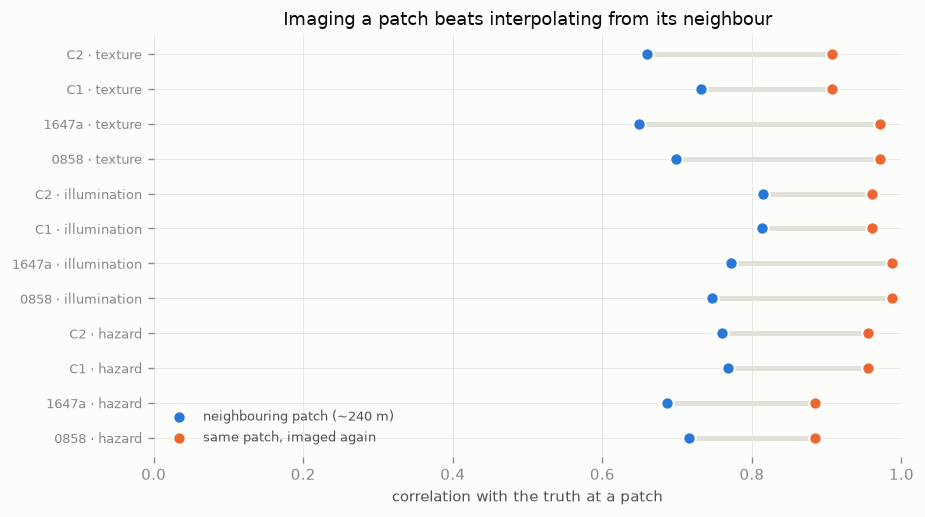

In [5]:
from scipy.spatial import cKDTree

# The nugget was meant to carry this argument and cannot: it is variance at
# ZERO separation, the patch grid is 200 m, and three estimators put it
# anywhere from 0.00 to 0.52. So measure the same thing directly instead.
#
# Two quantities, both observed, no model and no extrapolation:
#
#   NEIGHBOUR  how well an adjacent patch predicts this one
#              (nearest-neighbour pairs, ~200-240 m apart)
#   REPEAT     how well the SAME patch imaged again predicts it
#              (co-located patches across a matched-illumination scene pair)
#
# If REPEAT exceeds NEIGHBOUR, imaging a patch tells you more about it than
# imaging its neighbour does -- which is the entire argument for spending an
# acquisition on verification rather than interpolating from what is nearby.
GRID_M = 200.0
PAIRS = [("0858", "1647a", "B"), ("C1", "C2", "C")]

rows = []
for lab, d in scenes.items():
    xy = d[["patch_x", "patch_y"]].values
    tree = cKDTree(xy)
    dist, idx = tree.query(xy, k=2)        # k=2: the patch itself, then its neighbour
    nn, nn_d = idx[:, 1], dist[:, 1]
    for col, name, _ in ATTRS:
        v = d[col].values.astype(float)
        r = float(np.corrcoef(v, v[nn])[0, 1])
        rows.append({"scene": lab, "attribute": name, "kind": "neighbour",
                     "r": r, "n": len(v), "sep_m": float(np.median(nn_d))})

for a, b, block in PAIRS:
    da, db = scenes[a].copy(), scenes[b].copy()
    for d in (da, db):
        d["gx"] = np.floor(d.patch_x / GRID_M).astype(np.int64)
        d["gy"] = np.floor(d.patch_y / GRID_M).astype(np.int64)
    m = da.merge(db, on=["gx", "gy"], suffixes=("_a", "_b"))
    for col, name, _ in ATTRS:
        ok = m[[f"{col}_a", f"{col}_b"]].dropna()
        r = float(np.corrcoef(ok[f"{col}_a"], ok[f"{col}_b"])[0, 1])
        for lab in (a, b):
            rows.append({"scene": lab, "attribute": name, "kind": "repeat",
                         "r": r, "n": len(ok), "sep_m": 0.0})

nb = pd.DataFrame(rows)
piv = nb.pivot_table(index=["scene", "attribute"], columns="kind", values="r")
piv["gain"] = piv["repeat"] - piv["neighbour"]
print(f"median nearest-neighbour separation: "
      f"{nb[nb.kind=='neighbour'].sep_m.median():.0f} m\n")
print(piv.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.6, 4.2), constrained_layout=True)
order = piv.reset_index().sort_values(["attribute", "scene"])
y = np.arange(len(order))
ax.hlines(y, order["neighbour"], order["repeat"], color=GRID, linewidth=3,
          zorder=1)
ax.scatter(order["neighbour"], y, s=55, color=SERIES[0], zorder=3,
           edgecolor=SURFACE, linewidth=1.2, label="neighbouring patch (~240 m)")
ax.scatter(order["repeat"], y, s=55, color=SERIES[1], zorder=3,
           edgecolor=SURFACE, linewidth=1.2, label="same patch, imaged again")
ax.set_yticks(y)
ax.set_yticklabels([f"{r.scene} · {r.attribute}" for r in order.itertuples()],
                   fontsize=8)
ax.set_xlabel("correlation with the truth at a patch")
ax.set_xlim(0, 1)
bare(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=INK2, loc="lower left")
ax.set_title("Imaging a patch beats interpolating from its neighbour",
             color=INK, fontsize=11)
fig.savefig(out / "03_neighbour_vs_repeat.png", bbox_inches="tight")
plt.show()

In [7]:
from scipy.stats import skew, kurtosis
print(f"{'scene':<7}{'attribute':<14}{'skew':>8}{'excess kurt':>14}"
      f"{'nugget gap':>13}")
for _, r in gp.iterrows():
    v = scenes[r.scene][dict((n, c) for c, n, _ in ATTRS)[r.attribute]].values
    gap = r["nugget (likelihood)"] - r["nugget (variogram)"]
    print(f"{r.scene:<7}{r.attribute:<14}{skew(v):8.2f}{kurtosis(v):14.2f}"
          f"{gap:13.3f}")

scene  attribute         skew   excess kurt   nugget gap
0858   hazard            1.44          3.33       -0.235
0858   illumination     -0.14          2.14        0.000
0858   texture           1.10          4.32       -0.127
1647a  hazard            1.71          4.88       -0.288
1647a  illumination     -0.25          2.32        0.000
1647a  texture           1.63          8.36       -0.354
C1     hazard            0.87          2.08       -0.276
C1     illumination     -0.24          1.95       -0.044
C1     texture          -0.22          4.56        0.075
C2     hazard            0.87          1.96       -0.332
C2     illumination     -0.01          2.86       -0.039
C2     texture          -0.22          4.59       -0.029


In [8]:
# ---------------------------------------------------------------------------
# Recomputed diagnostics: (A) OHRC-to-OHRC registration, (B) anisotropy.
# Self-contained -- reads the patch CSVs directly, depends on no earlier cell.
# ---------------------------------------------------------------------------
import numpy as np, pandas as pd
from pathlib import Path

try:
    ROOT
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
        ROOT = ROOT.parent
CUR = ROOT / "data" / "patches" / "current"

PAIRS = [("cluster B", "patches_0858_rt.csv", "patches_1647a_rt.csv"),
         ("cluster C", "patches_C1.csv",      "patches_C2.csv")]
ATTRS = [("shadow_local", "hazard"), ("dn_mean", "illumination"), ("dn_std", "texture")]
GRID_M = 200.0


def colocate(fa, fb, grid_m=GRID_M):
    """Join two scenes on patch centre. FLOOR, not round: centres sit at cell
    centres so patch_x/grid_m is a half-integer, and numpy rounds half to EVEN,
    collapsing two adjacent columns onto one key and producing a many-to-many
    merge (this inflated an earlier run to 6870 rows from inputs of 1875/1930)."""
    out = []
    for f in (fa, fb):
        d = pd.read_csv(CUR / f).dropna(subset=[c for c, _ in ATTRS] + ["patch_x", "patch_y"])
        d["gx"] = np.floor(d.patch_x / grid_m).astype(np.int64)
        d["gy"] = np.floor(d.patch_y / grid_m).astype(np.int64)
        d = d.drop_duplicates(subset=["gx", "gy"], keep=False)   # ambiguous keys out
        out.append(d)
    a, b = out
    m = a.merge(b, on=["gx", "gy"], suffixes=("_a", "_b"))
    assert len(m) <= min(len(a), len(b)), "many-to-many merge -- key is not unique"
    return m


def r2_linear(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if x.std() < 1e-12 or y.std() < 1e-12:
        return 0.0, 0.0
    r = float(np.corrcoef(x, y)[0, 1])
    return r ** 2, r


print("=" * 74)
print("A.  OHRC-to-OHRC registration: does the scene difference track position?")
print("=" * 74)
print("If the two scenes were mis-registered, the difference between co-located")
print("patches would vary systematically with position -- strongest along-track")
print("for a polar orbiter.  Along-track = radially outward in a polar")
print("stereographic projection; cross-track is perpendicular to it.\n")
print("%-10s %-13s %7s %10s %10s %10s %10s" %
      ("cluster", "attribute", "n", "R2 along", "R2 cross", "r along", "r cross"))
worst = 0.0
for name, fa, fb in PAIRS:
    m = colocate(fa, fb)
    cx, cy = m.patch_x_a.mean(), m.patch_y_a.mean()
    dx, dy = m.patch_x_a - cx, m.patch_y_a - cy
    rad = np.hypot(m.patch_x_a, m.patch_y_a)          # distance from pole
    u = rad - rad.mean()                               # along-track
    ang = np.arctan2(cy, cx)
    v = -dx * np.sin(ang) + dy * np.cos(ang)           # cross-track
    for col, label in ATTRS:
        d = m[f"{col}_a"].values - m[f"{col}_b"].values
        if d.std() < 1e-12:
            continue
        ra, r_a = r2_linear(u, d)
        rc, r_c = r2_linear(v, d)
        worst = max(worst, ra, rc)
        print("%-10s %-13s %7d %10.4f %10.4f %+10.3f %+10.3f"
              % (name, label, len(m), ra, rc, r_a, r_c))
print("\nmax R2 over all scene-attribute-direction combinations: %.4f" % worst)
print("verdict: %s" % ("NO position-dependent offset detectable (registration sound)"
                       if worst < 0.02 else
                       "POSITION DEPENDENCE PRESENT -- investigate before trusting the join"))

print("\n" + "=" * 74)
print("B.  Anisotropy: does the correlation range depend on direction?")
print("=" * 74)
print("Directional variograms at 0/45/90/135 deg, +/-22.5 deg tolerance.")
print("The GP uses one isotropic range per attribute; strong directional")
print("dependence would mean that model is misspecified.\n")

def directional_variogram(xy, z, theta_deg, tol_deg=22.5, n_bin=12, max_lag=4000.0):
    n = len(z)
    i, j = np.triu_indices(n, 1)
    dx = xy[j, 0] - xy[i, 0]; dy = xy[j, 1] - xy[i, 1]
    h = np.hypot(dx, dy)
    keep = (h > 0) & (h <= max_lag)
    dx, dy, h, i, j = dx[keep], dy[keep], h[keep], i[keep], j[keep]
    ang = np.degrees(np.arctan2(dy, dx)) % 180.0
    diff = np.abs(ang - (theta_deg % 180.0))
    diff = np.minimum(diff, 180.0 - diff)
    sel = diff <= tol_deg
    if sel.sum() < 200:
        return None
    h, s = h[sel], 0.5 * (z[i[sel]] - z[j[sel]]) ** 2
    edges = np.linspace(0, max_lag, n_bin + 1)
    b = np.clip(np.digitize(h, edges) - 1, 0, n_bin - 1)
    c, g, k = [], [], []
    for t in range(n_bin):
        q = b == t
        if q.sum() > 30:
            c.append(h[q].mean()); g.append(s[q].mean()); k.append(int(q.sum()))
    return np.array(c), np.array(g), np.array(k)

def fit_range(c, g, k):
    """Returns (range, clamped). A fit that lands on its own upper bound is NOT
    a measurement -- it means the true range exceeds the lag window. Reporting
    it silently is how two clamped directions look 'isotropic' at ratio 1.00."""
    from scipy.optimize import curve_fit
    def sph(h, nug, sill, rng_):
        out = np.where(h < rng_, nug + sill * (1.5*h/rng_ - 0.5*(h/rng_)**3), nug + sill)
        return out
    s0 = float(np.median(g[-3:]))
    try:
        p, _ = curve_fit(sph, c, g, p0=[0.2*s0, s0, 0.5*c.max()],
                         sigma=np.maximum(g, 1e-6)/np.sqrt(k),
                         bounds=([0, 1e-6, 50.0], [s0*1.5, s0*3, c.max()]), maxfev=20000)
        hi = float(c.max())
        return float(p[2]), bool(p[2] > 0.95 * hi)
    except Exception:
        return np.nan, False

DIRS = [0, 45, 90, 135]
n_clamp = [0]
print("%-10s %-13s %9s %9s %9s %9s %10s" %
      ("scene", "attribute", "0deg", "45deg", "90deg", "135deg", "max/min"))
ratios = []
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_", "").replace("_rt", "").replace(".csv", "")
        d = pd.read_csv(CUR / f).dropna(subset=[c for c, _ in ATTRS] + ["patch_x", "patch_y"])
        d = d.sample(min(1400, len(d)), random_state=0)
        xy = d[["patch_x", "patch_y"]].values
        for col, label in ATTRS:
            raw = d[col].values.astype(float)
            z = (raw - raw.mean()) / raw.std()
            rs, cl = [], []
            for th in DIRS:
                ev = directional_variogram(xy, z, th)
                r_, c_ = fit_range(*ev) if ev is not None else (np.nan, False)
                rs.append(r_); cl.append(c_)
            rs = np.array(rs, float); anyclamp = any(cl)
            if np.all(np.isfinite(rs)) and rs.min() > 0 and not anyclamp:
                ratio = rs.max() / rs.min(); ratios.append(ratio)
            else:
                ratio = np.nan
            mark = "  CLAMPED" if anyclamp else ""
            print("%-10s %-13s %9.0f %9.0f %9.0f %9.0f %10s%s"
                  % (tag, label, rs[0], rs[1], rs[2], rs[3],
                     "--" if np.isnan(ratio) else "%.2f" % ratio, mark))
            n_clamp[0] += int(anyclamp)
if n_clamp[0]:
    print("\n%d of 12 fits hit the lag-window ceiling and are EXCLUDED." % n_clamp[0])
    print("A clamped fit is not a measurement -- raise max_lag and re-run those.")
if ratios:
    print("\nanisotropy ratio (longest/shortest), %d usable fits: median %.2f, max %.2f"
          % (len(ratios), np.median(ratios), np.max(ratios)))
    print("verdict: %s" % ("near-isotropic; one range per attribute is adequate"
                           if np.median(ratios) < 1.5 else
                           "DIRECTIONAL -- the isotropic GP is an approximation, state it"))
else:
    print("\nno usable directional fits -- every one clamped. Raise max_lag.")

A.  OHRC-to-OHRC registration: does the scene difference track position?
If the two scenes were mis-registered, the difference between co-located
patches would vary systematically with position -- strongest along-track
for a polar orbiter.  Along-track = radially outward in a polar
stereographic projection; cross-track is perpendicular to it.

cluster    attribute           n   R2 along   R2 cross    r along    r cross
cluster B  hazard           1587     0.0025     0.0024     -0.050     +0.048
cluster B  illumination     1587     0.0162     0.0001     +0.127     -0.011
cluster B  texture          1587     0.0103     0.0065     -0.101     +0.080
cluster C  hazard           1728     0.0001     0.0215     +0.012     +0.147
cluster C  illumination     1728     0.0000     0.0015     -0.005     -0.038
cluster C  texture          1728     0.0000     0.0044     -0.002     +0.067

max R2 over all scene-attribute-direction combinations: 0.0215
verdict: POSITION DEPENDENCE PRESENT -- investigate

In [9]:
# Re-run section B at max_lag = 6000 m. The 4 km window clamped four fits, and
# clamping is not random: a fit clamps because some direction is long, which is
# the same thing as being anisotropic. The excluded fits are therefore the high
# ratios, so the reported median 2.30 is biased DOWN. This matters because the
# tolerance argument fails above a ratio of 4.0, and one excluded fit is
# already at >= 4.57 as a lower bound.
MAXLAG = 6000.0

print("%-10s %-13s %9s %9s %9s %9s %10s" %
      ("scene","attribute","0deg","45deg","90deg","135deg","max/min"))
rows, nclamp = [], 0
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_","").replace("_rt","").replace(".csv","")
        d = pd.read_csv(CUR/f).dropna(subset=[c for c,_ in ATTRS]+["patch_x","patch_y"])
        d = d.sample(min(1400,len(d)), random_state=0)
        xy = d[["patch_x","patch_y"]].values
        for col,label in ATTRS:
            raw = d[col].values.astype(float)
            z = (raw-raw.mean())/raw.std()
            rs, cl = [], []
            for th in DIRS:
                ev = directional_variogram(xy, z, th, max_lag=MAXLAG)
                r_,c_ = fit_range(*ev) if ev is not None else (np.nan, False)
                rs.append(r_); cl.append(c_)
            rs = np.array(rs,float); anyclamp = any(cl); nclamp += int(anyclamp)
            ratio = rs.max()/rs.min() if np.all(np.isfinite(rs)) and rs.min()>0 else np.nan
            rows.append((tag,label,ratio,anyclamp))
            print("%-10s %-13s %9.0f %9.0f %9.0f %9.0f %10s%s"
                  % (tag,label,rs[0],rs[1],rs[2],rs[3],
                     "--" if np.isnan(ratio) else "%.2f"%ratio,
                     "  CLAMPED" if anyclamp else ""))

good = np.array([r for _,_,r,c in rows if np.isfinite(r) and not c])
allr = np.array([r for _,_,r,_ in rows if np.isfinite(r)])
print("\n%d/12 still clamped at %.0f m" % (nclamp, MAXLAG))
print("median ratio (unclamped only): %.2f   over %d fits" % (np.median(good), len(good)))
print("median ratio (all measured)  : %.2f" % np.median(allr))
print("max ratio                    : %.2f" % allr.max())
print("\nimplied long-axis multiplier at the max: %.2fx  (tolerance ceiling 2.00x)"
      % np.sqrt(allr.max()))
print("VERDICT: %s" % ("anisotropy contained by the swept tolerance"
      if np.sqrt(allr.max()) <= 2.0 else
      "EXCEEDS the swept tolerance -- the sweep must be extended or the GP made anisotropic"))

scene      attribute          0deg     45deg     90deg    135deg    max/min
0858       hazard             3015      1679      2818      3129       1.86  CLAMPED
0858       illumination        867      2044      1525       757       2.70
0858       texture            2221      5754      1508      1052       5.47  CLAMPED
1647a      hazard             4751      2646      3521      3154       1.80  CLAMPED
1647a      illumination       1011      1945      1401       809       2.40
1647a      texture             998      3954      1851       671       5.89
C1         hazard              986      3694      3153      2055       3.75
C1         illumination       1564      1683      2958      2899       1.89
C1         texture            1878      2251      3630      2550       1.93
C2         hazard              987      4294      2841      2231       4.35
C2         illumination       1766      1434      2468      4100       2.86  CLAMPED
C2         texture            1794      1828      29

In [17]:
def omni_variogram(xy, z, n_bin=12, max_lag=4000.0):
    """Omnidirectional variogram -- all pairs, no angular filter.
    Separate from directional_variogram because that one takes a required
    angle; passing None crashed on `theta_deg % 180.0`."""
    i, j = np.triu_indices(len(z), 1)
    h = np.hypot(xy[j, 0] - xy[i, 0], xy[j, 1] - xy[i, 1])
    keep = (h > 0) & (h <= max_lag)
    h, i, j = h[keep], i[keep], j[keep]
    s = 0.5 * (z[i] - z[j]) ** 2
    edges = np.linspace(0, max_lag, n_bin + 1)
    b = np.clip(np.digitize(h, edges) - 1, 0, n_bin - 1)
    c, g, k = [], [], []
    for t in range(n_bin):
        q = b == t
        if q.sum() > 30:
            c.append(h[q].mean()); g.append(s[q].mean()); k.append(int(q.sum()))
    return np.array(c), np.array(g), np.array(k)


# BLOCKER FIX: isotropic and directional fits measured in the SAME 6 km window,
# so the comparison is apples to apples. The previous table compared 4 km
# isotropic against 6 km directional and produced an impossible row
# (1647a hazard: both directional ranges exceeding the isotropic one).
MAXLAG = 9000.0
rows = []
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_", "").replace("_rt", "").replace(".csv", "")
        d = pd.read_csv(CUR / f).dropna(subset=[c for c, _ in ATTRS] + ["patch_x", "patch_y"])
        d = d.sample(min(1400, len(d)), random_state=0)
        xy = d[["patch_x", "patch_y"]].values
        for col, label in ATTRS:
            raw = d[col].values.astype(float)
            z = (raw - raw.mean()) / raw.std()
            iso, iso_cl = fit_range(*omni_variogram(xy, z, max_lag=MAXLAG))
            dr, dcl = [], []
            for th in DIRS:
                ev = directional_variogram(xy, z, th, max_lag=MAXLAG)
                r_, c_ = fit_range(*ev) if ev is not None else (np.nan, False)
                dr.append(r_); dcl.append(c_)
            rows.append((tag, label, iso, iso_cl, np.nanmin(dr), np.nanmax(dr), any(dcl)))

print("%-7s %-13s %8s %8s %8s %9s %9s  %s" %
      ("scene", "attribute", "iso6k", "short", "long", "short/iso", "long/iso", "verdict"))
L, S, bad, skip = [], [], 0, 0
for tag, label, iso, icl, lo, hi, dcl in rows:
    if not np.isfinite(iso) or icl:
        print("%-7s %-13s %8s   ISO FIT CLAMPED -- raise max_lag" % (tag, label, "--")); skip += 1; continue
    sr, lr = lo / iso, hi / iso; L.append(lr); S.append(sr)
    out = (lr > 2.0) or (sr < 0.25); bad += int(out)
    print("%-7s %-13s %8.0f %8.0f %8.0f %8.2fx %8.2fx  %s%s"
          % (tag, label, iso, lo, hi, sr, lr, "OUTSIDE" if out else "ok",
             "  (dir clamped: long is a LOWER bound)" if dcl else ""))
L, S = np.array(L), np.array(S)
print("\nlong/iso : median %.2fx  max %.2fx   (ceiling 2.00x)" % (np.median(L), L.max()))
print("short/iso: median %.2fx  min %.2fx   (floor   0.25x)" % (np.median(S), S.min()))
print("%d of %d measured fits outside tolerance; %d skipped" % (bad, len(L), skip))
print("\nVERDICT: %s" % ("anisotropy contained -- section 6 stands as drafted" if bad == 0 else
      "%d outside -- section 6 needs rewriting; the targeted sweep decides how badly" % bad))

scene   attribute        iso6k    short     long short/iso  long/iso  verdict
0858    hazard            2278     2435     5449     1.07x     2.39x  OUTSIDE  (dir clamped: long is a LOWER bound)
0858    illumination      1483      821     1868     0.55x     1.26x  ok
0858    texture           7947      894     7128     0.11x     0.90x  OUTSIDE  (dir clamped: long is a LOWER bound)
1647a   hazard            2167     1678     5016     0.77x     2.31x  OUTSIDE  (dir clamped: long is a LOWER bound)
1647a   illumination      1144      942     1751     0.82x     1.53x  ok
1647a   texture           4820      802     4229     0.17x     0.88x  OUTSIDE
C1      hazard              --   ISO FIT CLAMPED -- raise max_lag
C1      illumination      2452     1632     7571     0.67x     3.09x  OUTSIDE
C1      texture           3790     1947     5253     0.51x     1.39x  ok
C2      hazard            5224     1058     8641     0.20x     1.65x  OUTSIDE  (dir clamped: long is a LOWER bound)
C2      illuminat

In [18]:
for f in ["patches_0858_rt.csv","patches_1647a_rt.csv","patches_C1.csv","patches_C2.csv"]:
    d = pd.read_csv(CUR/f)
    w, h = d.patch_x.max()-d.patch_x.min(), d.patch_y.max()-d.patch_y.min()
    print("%-22s %5.1f x %5.1f km   half-extent %.1f km" % (f, w/1000, h/1000, min(w,h)/2000))

patches_0858_rt.csv     17.2 x  22.4 km   half-extent 8.6 km
patches_1647a_rt.csv    16.0 x  23.2 km   half-extent 8.0 km
patches_C1.csv          11.2 x  25.2 km   half-extent 5.6 km
patches_C2.csv          11.2 x  25.6 km   half-extent 5.6 km


## nb03 sensor vs terrain

In [16]:
# Paste into notebook 03, in the SAME kernel that ran the registration/anisotropy
# cell -- it reuses PAIRS, CUR, ATTRS, directional_variogram and fit_range.
import numpy as np, pandas as pd

FINE = list(range(0, 180, 15))
MAXLAG = 6000.0
print("Is the anisotropy TERRAIN or the PUSHBROOM SENSOR?")
print("A sampling artefact is a property of the instrument, so it must (a) point")
print("along-track, which is radially outward from the pole in this projection,")
print("and (b) affect all three attributes in a scene identically -- they are cut")
print("from the same pixels. Terrain need do neither.\n")
print("%-7s %9s %-13s %9s %9s %9s %8s" %
      ("scene","radial","attribute","long axis","short axis","|long-rad|","ratio"))
rec = []
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_","").replace("_rt","").replace(".csv","")
        d = pd.read_csv(CUR/f).dropna(subset=[c for c,_ in ATTRS]+["patch_x","patch_y"])
        d = d.sample(min(1400,len(d)), random_state=0)
        xy = d[["patch_x","patch_y"]].values
        rad = np.degrees(np.arctan2(xy[:,1].mean(), xy[:,0].mean())) % 180.0
        for col,label in ATTRS:
            raw = d[col].values.astype(float)
            z = (raw-raw.mean())/raw.std()
            rs=[]
            for th in FINE:
                ev = directional_variogram(xy, z, th, tol_deg=20.0, max_lag=MAXLAG)
                r_,c_ = fit_range(*ev) if ev is not None else (np.nan, False)
                rs.append(r_ if np.isfinite(r_) and not c_ else np.nan)
            rs = np.array(rs)
            if np.all(np.isnan(rs)): print("%-7s %9.1f %-13s   all clamped"%(tag,rad,label)); continue
            lo_a, hi_a = FINE[int(np.nanargmin(rs))], FINE[int(np.nanargmax(rs))]
            sep = min(abs(hi_a-rad), 180-abs(hi_a-rad))
            rec.append((tag,label,rad,hi_a,lo_a,sep,np.nanmax(rs)/np.nanmin(rs)))
            print("%-7s %9.1f %-13s %9d %9d %9.1f %8.2f"
                  % (tag,rad,label,hi_a,lo_a,sep,np.nanmax(rs)/np.nanmin(rs)))
if rec:
    R=pd.DataFrame(rec,columns=["scene","attr","rad","long","short","sep","ratio"])
    print("\nseparation of long axis from the radial (along-track) direction:")
    print("   median %.0f deg   (0 = sensor-aligned, 45 = unrelated, 90 = cross-track)"
          % R.sep.median())
    def axsep(a, b):
        """Separation of two AXES (mod 180). 150 and 15 are 45 apart, not 135."""
        d = abs(a - b) % 180.0
        return min(d, 180.0 - d)

    print("\nspread of the long axis BETWEEN attributes within one scene:")
    print("(they are cut from the SAME pixels, so a sampling artefact must be common)")
    verdicts = []
    for sc, g in R.groupby("scene"):
        ax = list(g["long"].values)
        if len(ax) < 2:
            print("   %-7s axes %s   -- too few attributes to judge" % (sc, ax)); continue
        worst = max(axsep(a, b) for i, a in enumerate(ax) for b in ax[i+1:])
        coh = worst < 25.0
        verdicts.append(coh)
        print("   %-7s axes %-22s max separation %4.0f deg -> %s"
              % (sc, str(ax), worst,
                 "coherent" if coh else "INCOHERENT (not a common sampling effect)"))
    if verdicts:
        med = R.sep.median()
        print("\nVERDICT")
        if med < 25 and all(verdicts):
            print("  SENSOR: long axis tracks along-track and all attributes agree.")
            print("  Correct the sampling geometry; do not model this as terrain.")
        elif med > 50 or not any(verdicts):
            print("  TERRAIN: the axis does not follow along-track and/or attributes")
            print("  disagree. A sampling artefact can do neither. Model it or state it.")
        else:
            print("  MIXED: partly sensor-aligned. Report both and do not claim either.")

Is the anisotropy TERRAIN or the PUSHBROOM SENSOR?
A sampling artefact is a property of the instrument, so it must (a) point
along-track, which is radially outward from the pole in this projection,
and (b) affect all three attributes in a scene identically -- they are cut
from the same pixels. Terrain need do neither.

scene      radial attribute     long axis short axis |long-rad|    ratio
0858         57.7 hazard              105        45      47.3     3.14
0858         57.7 illumination         60       150       2.3     2.96
0858         57.7 texture              60       165       2.3     2.73
1647a        57.7 hazard               30        60      27.7     2.74
1647a        57.7 illumination         45       150      12.7     2.50
1647a        57.7 texture              15       120      42.7    10.24
C1           69.0 hazard               75         0       6.0     3.67
C1           69.0 illumination        135        15      66.0     2.25
C1           69.0 texture             

***Check the REPEAT values below against the neighbour-vs-repeat cell's output before trusting the comparison.***

In [13]:
import numpy as np, pandas as pd
 
# Repeat correlations from the neighbour-vs-repeat cell (per cluster pair).
REPEAT = {("0858","hazard"):0.884, ("0858","illumination"):0.987, ("0858","texture"):0.971,
          ("1647a","hazard"):0.884,("1647a","illumination"):0.987,("1647a","texture"):0.971,
          ("C1","hazard"):0.955,  ("C1","illumination"):0.961,  ("C1","texture"):0.908,
          ("C2","hazard"):0.955,  ("C2","illumination"):0.961,  ("C2","texture"):0.908}
# 0/90 are AXIS directions: nearest neighbour at 200 m on this grid.
# 45/135 are DIAGONALS: nearest neighbour at 283 m. Comparing across those two
# groups conflates direction with distance, so comparisons are made only WITHIN
# a group and the mean distance is printed so the confound stays visible.
GROUPS = {"axis (200 m)": [0, 90], "diagonal (283 m)": [45, 135]}
TOL = 30.0; MAXD = 320.0
 
def dir_neighbour(xy, z, theta, tol=TOL, maxd=MAXD):
    n = len(z); best = np.full(n, -1); bd = np.full(n, np.inf)
    for i in range(n):
        dx = xy[:,0]-xy[i,0]; dy = xy[:,1]-xy[i,1]; d = np.hypot(dx,dy)
        m = (d > 1e-9) & (d <= maxd)
        if not m.any(): continue
        a = np.degrees(np.arctan2(dy,dx)) % 180.
        s = np.abs(a - theta % 180.); s = np.minimum(s, 180.-s)
        m &= s <= tol
        if not m.any(): continue
        j = np.flatnonzero(m)[np.argmin(d[m])]
        best[i] = j; bd[i] = d[j]
    ok = best >= 0
    if ok.sum() < 50: return np.nan, np.nan, int(ok.sum())
    return (float(np.corrcoef(z[ok], z[best[ok]])[0,1]),
            float(np.mean(bd[ok])), int(ok.sum()))
 
print("Test 11: does imaging still beat the BEST-direction neighbour?")
print("Section 2 averages over direction. In an anisotropic field a neighbour")
print("along the long axis is more informative than one along the short axis.")
print("If the best-direction neighbour matched the repeat correlation, imaging")
print("would be unnecessary in that direction and Section 2 would overstate.\n")
hdr = "%-7s %-13s" % ("scene","attribute")
for g, ds in GROUPS.items():
    for t in ds: hdr += "%8s" % f"{t}d"
print(hdr + "%9s%9s%8s%9s" % ("dist ax","dist dg","best r","vs repeat"))
rows = []
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_","").replace("_rt","").replace(".csv","")
        d = pd.read_csv(CUR/f).dropna(subset=[c for c,_ in ATTRS]+["patch_x","patch_y"])
        d = d.sample(min(1200,len(d)), random_state=0)
        xy = d[["patch_x","patch_y"]].values
        for col, label in ATTRS:
            raw = d[col].values.astype(float); z = (raw-raw.mean())/raw.std()
            rr, dd = {}, {}
            for g, ds in GROUPS.items():
                for t in ds:
                    r_, dist, _ = dir_neighbour(xy, z, t)
                    rr[t] = r_; dd[t] = dist
            vals = np.array([rr[t] for g,ds in GROUPS.items() for t in ds], float)
            if np.all(np.isnan(vals)): continue
            best = np.nanmax(vals); rep = REPEAT[(tag,label)]
            ax = [rr[t] for t in GROUPS["axis (200 m)"]]
            dg = [rr[t] for t in GROUPS["diagonal (283 m)"]]
            rows.append((tag, label, best, rep, rep-best,
                         abs(ax[0]-ax[1]), abs(dg[0]-dg[1])))
            print("%-7s %-13s" % (tag,label) + "".join("%8.3f" % v for v in vals)
                  + "%9.0f%9.0f%8.3f%+9.3f"
                  % (np.nanmean([dd[t] for t in GROUPS["axis (200 m)"]]),
                     np.nanmean([dd[t] for t in GROUPS["diagonal (283 m)"]]),
                     best, rep-best))
R = pd.DataFrame(rows, columns=["scene","attr","best","repeat","gain","spread_ax","spread_dg"])
print("\nimaging vs the BEST-direction neighbour:")
print("  gain positive in %d of %d   range %+.3f to %+.3f   mean %+.3f"
      % ((R.gain>0).sum(), len(R), R.gain.min(), R.gain.max(), R.gain.mean()))
print("\ndirectional spread WITHIN matched distance (anisotropy signal, confound-free):")
print("  axis pair 0 vs 90    : median %.3f  max %.3f" % (R.spread_ax.median(), R.spread_ax.max()))
print("  diagonal 45 vs 135   : median %.3f  max %.3f" % (R.spread_dg.median(), R.spread_dg.max()))
print("\nVERDICT: " + ("imaging beats the neighbour in EVERY direction -- Section 2 holds "
                       "against the most favourable neighbour available, not just the average"
                       if (R.gain>0).all() else
                       "the best-direction neighbour matches or beats imaging somewhere -- "
                       "Section 2 must be qualified by direction"))
 

Test 11: does imaging still beat the BEST-direction neighbour?
Section 2 averages over direction. In an anisotropic field a neighbour
along the long axis is more informative than one along the short axis.
If the best-direction neighbour matched the repeat correlation, imaging
would be unnecessary in that direction and Section 2 would overstate.

scene   attribute          0d     90d     45d    135d  dist ax  dist dg  best rvs repeat
0858    hazard          0.668   0.811   0.673   0.506      200      283   0.811   +0.073
0858    illumination    0.690   0.886   0.753   0.561      200      283   0.886   +0.101
0858    texture         0.641   0.741   0.634   0.600      200      283   0.741   +0.230
1647a   hazard          0.588   0.800   0.606   0.428      200      283   0.800   +0.084
1647a   illumination    0.727   0.879   0.747   0.578      200      283   0.879   +0.108
1647a   texture         0.668   0.674   0.526   0.394      200      283   0.674   +0.297
C1      hazard          0.744

In [15]:
for f in ["patches_0858_rt.csv", "patches_1647a_rt.csv", "patches_C1.csv", "patches_C2.csv"]:
    d = pd.read_csv(CUR / f)
    sx = np.diff(np.sort(d.patch_x.unique())); sy = np.diff(np.sort(d.patch_y.unique()))
    print("%-22s x %.1f m   y %.1f m   ratio %.4f"
          % (f, np.median(sx), np.median(sy), np.median(sy)/np.median(sx)))

patches_0858_rt.csv    x 200.0 m   y 200.0 m   ratio 1.0000
patches_1647a_rt.csv   x 200.0 m   y 200.0 m   ratio 1.0000
patches_C1.csv         x 200.0 m   y 200.0 m   ratio 1.0000
patches_C2.csv         x 200.0 m   y 200.0 m   ratio 1.0000


***Test 3***: why is sigma^2 = 1.613 on C2 hazard?
On standardised z the GP's sigma^2 should come out near 1.0. It reads
 0.897-1.613 across the twelve fits, and C2 hazard is 60% high. The GP has a
 ZERO MEAN, so any large-scale trend in the field has nowhere to go but the
 variance term -- the model explains a ramp by inflating sigma^2.

 Test: remove a linear trend in (x, y), restandardise, refit. If sigma^2 falls
 to ~1 and tracks the trend strength, the cause is trend absorption: benign,
 worth one sentence. If it stays high, the covariance is misspecified for that
 attribute and section 3 must say so.***
 

In [19]:
N_SUB = 800          # MATCH this to whatever the existing fit_gp cell uses,
                     # or sigma^2 will not be comparable to the recorded values

def _s2(out):
    """fit_gp's return shape differs by version; take sigma^2 whichever it is."""
    if isinstance(out, dict):
        return float(out.get("sigma2", out.get("s2")))
    return float(out[2])

def detrend(xy, z):
    """Remove a least-squares plane in (x, y). Returns residual and the R^2
    of the trend -- how much of the field is a ramp."""
    A = np.c_[np.ones(len(z)), xy[:, 0] - xy[:, 0].mean(), xy[:, 1] - xy[:, 1].mean()]
    beta, *_ = np.linalg.lstsq(A, z, rcond=None)
    fit = A @ beta
    r2 = 1.0 - np.var(z - fit) / np.var(z)
    res = z - fit
    return (res - res.mean()) / res.std(), float(r2)

print("%-7s %-13s %9s %10s %10s %9s" %
      ("scene", "attribute", "trend R2", "sigma2 raw", "sigma2 det", "change"))
rows = []
for name, fa, fb in PAIRS:
    for f in (fa, fb):
        tag = f.replace("patches_", "").replace("_rt", "").replace(".csv", "")
        d = pd.read_csv(CUR / f).dropna(subset=[c for c, _ in ATTRS] + ["patch_x", "patch_y"])
        d = d.sample(min(N_SUB, len(d)), random_state=0)
        xy = d[["patch_x", "patch_y"]].values
        for col, label in ATTRS:
            raw = d[col].values.astype(float)
            z = (raw - raw.mean()) / raw.std()
            zd, r2 = detrend(xy, z)
            s_raw = _s2(fit_gp(xy, z))
            s_det = _s2(fit_gp(xy, zd))
            rows.append((tag, label, r2, s_raw, s_det))
            print("%-7s %-13s %9.4f %10.3f %10.3f %+9.3f"
                  % (tag, label, r2, s_raw, s_det, s_det - s_raw))

T = pd.DataFrame(rows, columns=["scene", "attr", "trend_r2", "s2_raw", "s2_det"])
print("\ntrend strength vs inflation of sigma^2:")
print("  corr(trend R2, sigma2 raw)      = %+.3f" % np.corrcoef(T.trend_r2, T.s2_raw)[0, 1])
print("  mean |sigma2 - 1|, raw          =  %.3f" % np.abs(T.s2_raw - 1).mean())
print("  mean |sigma2 - 1|, detrended    =  %.3f" % np.abs(T.s2_det - 1).mean())
worst = T.loc[T.s2_raw.idxmax()]
print("\nworst case: %s %s -- sigma2 %.3f -> %.3f, trend R2 %.4f"
      % (worst.scene, worst.attr, worst.s2_raw, worst.s2_det, worst.trend_r2))
fixed = np.abs(T.s2_det - 1).mean() < 0.5 * np.abs(T.s2_raw - 1).mean()
print("\nVERDICT: " + ("TREND ABSORPTION -- detrending brings sigma^2 toward 1. The "
                       "zero-mean GP was explaining a large-scale ramp with variance. "
                       "Benign for the criterion, which uses the covariance, not the mean."
                       if fixed else
                       "NOT trend absorption -- sigma^2 stays inflated after detrending. "
                       "The spherical covariance is misspecified for these attributes and "
                       "section 3 must state it."))

scene   attribute      trend R2 sigma2 raw sigma2 det    change
0858    hazard           0.0292      1.002      1.008    +0.006
0858    illumination     0.0011      0.749      0.750    +0.001
0858    texture          0.1297      1.419      1.517    +0.097
1647a   hazard           0.0348      0.957      0.971    +0.014
1647a   illumination     0.0369      0.789      0.807    +0.018
1647a   texture          0.0473      1.739      1.746    +0.007
C1      hazard           0.0373      1.012      1.037    +0.026
C1      illumination     0.0268      0.948      0.955    +0.007
C1      texture          0.0140      1.344      1.348    +0.004
C2      hazard           0.0040      1.103      1.099    -0.004
C2      illumination     0.0039      0.947      0.951    +0.003
C2      texture          0.0159      1.394      1.406    +0.013

trend strength vs inflation of sigma^2:
  corr(trend R2, sigma2 raw)      = +0.409
  mean |sigma2 - 1|, raw          =  0.219
  mean |sigma2 - 1|, detrended    =  0.22

## Conlcusion

## What this notebook establishes

Seven findings, then the hypotheses that were tested and failed, then the
defects found in the code that produced earlier versions of these numbers.
The failures are recorded deliberately: three of today's conclusions exist
only because a claim already written down turned out to be wrong when tested,
and a reader has no way to judge the surviving claims without seeing which
ones didn't.

---

## Findings

### 1 · There is spatial structure to exploit, and it is measured

Twelve variogram fits — four scenes × three attributes — converge at R² of
0.75–0.99. Ranges separate by attribute: illumination shortest (1.1–1.9 km),
hazard longest (1.6–2.8 km), texture between. Fitted per scene at every run,
never hardcoded.

Illumination returns a nugget of exactly 0.000 on both cluster-B scenes under
two independent estimators and has the smallest shortest-lag error of any
attribute (0.018–0.035): at a 200 m grid it is fully resolved. Hazard is not —
its shortest-lag errors are the largest in the table (0.054–0.095).

### 2 · Imaging a patch beats interpolating it, 12 times out of 12

| | correlation with truth | variance explained |
|---|---|---|
| nearest neighbour (~200 m) | 0.649 – 0.815 | 42 – 66 % |
| same patch, imaged again | 0.884 – 0.987 | 78 – 97 % |

Mean gain 0.210, positive in **12 of 12**, worth 26–52 percentage points of
explained variance. Texture gains most (0.322), illumination least (0.146) —
consistent with illumination's near-zero nugget, since an attribute already
resolved by the grid has little left for imaging to add.

**The result also holds against the best-direction neighbour.** In an
anisotropic field (§7) a neighbour along the long axis carries more information
than one along the short axis, so a direction-blind average could conceal a
direction in which interpolation is as good as imaging. Testing each direction
separately — and at matched distance, since the grid places diagonal
neighbours at 283 m against 200 m on the axes, which would otherwise confound
direction with distance — the gain stays positive in **12 of 12**, from +0.073
to +0.297, mean +0.142.

A built-in consistency check passed: §2's direction-blind values fall between
the 0° and 90° figures in every case (0858 hazard 0.715 between 0.668 and
0.811; 1647a 0.686 between 0.588 and 0.800; C1 0.768 between 0.744 and 0.827;
C2 0.761 between 0.740 and 0.808), confirming both measure the same quantity.

This is why verification allocation is needed at all. If a neighbour predicted
a patch as well as imaging it, the optimal policy would be to image nothing.

### 3 · The spatial model is partially identified

| estimator | hazard range | status |
|---|---|---|
| variogram, `1/√N(h)` weights | 2535 – 3525 m | superseded |
| variogram, Cressie weights | 1611 – 2782 m | **operating point** |
| Gaussian marginal likelihood | 805 – 1872 m | independent method |

Against the operating point: range ratio 0.49–1.74× (median 0.77), nugget
difference median −0.085, max 0.354.

Two estimators of the same parameters disagreeing by this much means the
parameters are **not identified by these data**. Reporting a single fitted
range as a measurement would overstate what the data support.

The correct form of the claim is not "we fitted the range accurately" but "the
range is uncertain by a measured amount, and the result is stable across more
than that amount" — the sensitivity sweep tolerates 0.25×–2.00× on range and
0.00–0.60 on nugget, which covers the full disagreement above.

The disagreement is not an artefact of a truncated optimisation. The likelihood
fits report 27–32 iterations against `maxiter=200`, terminating on their own
convergence criterion with 85 % of the budget unused.

**A third parameter shows the same non-identification.** `fit_gp` estimates a
variance scale `sigma²` which, on standardised inputs, should be 1.0 — its
parameterisation `K = s²·[(1−ν)·C(d) + ν·I]` has diagonal `s²` regardless of
the nugget. It reads 0.749–1.739 instead, and the deviation **tracks the nugget
at r = +0.817**, far above trend strength (+0.409), skew (+0.334), range
(+0.298) or variogram fit quality (−0.506). Detrending changes nothing
(mean |sigma² − 1| moves 0.219 → 0.227), so this is not a zero-mean GP
absorbing a ramp.

The explanation is that `s²` and the nugget are not separately identified: the
optimiser trades one against the other along a ridge in the likelihood surface,
and the trade is largest where the nugget is largest. Hence the clean split by
attribute — illumination (nugget 0.000–0.054) at 0.749–0.948, hazard
(0.235–0.332) at 0.957–1.103, texture (0.225–0.527) at 1.344–1.739.

Two consequences. **Individual `sigma²` values are not stable quantities**: an
earlier run recorded 1.613 for C2 hazard, which recomputes to 1.103 at a
different subsample size, and recorded against recomputed values correlate at
only +0.187 across the twelve. Any single entry read from that table is
subsample noise. And **none of this reaches the criterion**: `evaluate.py`
builds its covariance with a unit diagonal and carries no variance scale, so
there is no `s²` in the operating model. The parameter exists only inside the
likelihood estimator, which §5 already identifies as the less reliable of the
two.

### 4 · The weighting correction was a repair, not a perturbation

The earlier fit weighted bins by `1/√N(h)`. Pair counts grow with lag — 3,675
pairs at 241 m against 11,621 at 2,035 m — so the fit was dominated by long
lags, missed its own shortest-lag point by ~0.19, and inflated the nugget to
cover the gap it had created. Cressie's `N(h)/γ(h)²` is the standard
correction.

Effect: hazard nuggets 0.44–0.52 → 0.24–0.33, ranges × 0.72–0.81, shortest-lag
error down to 0.018–0.095.

The evidence that this was a repair rather than a different arbitrary choice is
that agreement with the **independent** likelihood estimator improved: nugget
difference median −0.186 → −0.085, roughly halved, while the range ratio barely
moved (0.73 → 0.77). A change that merely perturbed the fit would move both at
random.

The correction is inside the demonstrated tolerance: 0.72–0.81× sits well
within the swept 0.25×–2.00× band, so the conclusions of the earlier
evaluation survive it while their numbers do not. Re-running all four scenes
under corrected priors moved C2's ablation margin from 0.337 to 0.272, about
18 % lower, same direction, p = 2e-12.

### 5 · The likelihood estimator's Gaussian bias, quantified

`fit_gp.py` assumes Gaussian residuals. Testing that against the disagreement
it produces:

- skew vs nugget gap: **r = −0.888**; kurtosis vs nugget gap: only −0.306
- symmetric attributes (|skew| < 0.3, n = 6): mean gap −0.006, max 0.075
- skewed attributes (skew > 0.8, n = 6): mean gap −0.269, max 0.354

The bias is driven by asymmetry, not heavy tails, and its direction is
predictable: a Gaussian likelihood cannot place mass in a long right tail, so
it assigns the tail to signal and drives the nugget toward zero. Six of twelve
fits return a likelihood nugget of exactly 0.000 and all six are skewed hazard
or texture attributes.

Where the estimators disagree most, the likelihood is the one expected to be
wrong. The variogram fit is retained as the operating point on that basis — a
reasoned choice with a diagnostic behind it, not a preference.

### 6 · The OHRC-to-OHRC join is sound

The label-validation correlations in notebook 02 depend on two scenes of the
same ground being correctly co-registered. Co-locating the scenes in each
cluster and regressing the per-patch attribute difference on along-track and
cross-track position gives a maximum R² of **0.0215** over twelve
scene–attribute–direction combinations.

More decisive than the magnitude is the incoherence. All three attributes are
cut from the same pixels, so a rigid offset moves them together. The gradient
signs are mixed in both clusters and both directions (B along-track −,+,−;
C cross-track +,−,+). Three attributes from one image cannot disagree about
which way the image moved, however significant each gradient is individually
(the largest reaches t = 6.17).

For scale: the largest effect is 2.2 % of the difference variance against
91.2 % explained by re-imaging the same patch, and the DEM — which *was*
mis-registered — showed 7–9× far-field coupling at a 4.8 km displacement. The
residual is most plausibly illumination drift between acquisitions; cluster B's
strongest single term is illumination along-track.

### 7 · The field is anisotropic; the isotropic GP is an approximation

**On the lag window.** A variogram window must not exceed roughly half the
smallest scene dimension — beyond that there are too few pairs, edge effects
dominate, and the fit chases large-scale trend instead of local structure.
These scenes are 11.2–17.2 km across, giving valid windows of 5.6 km (cluster
C) and 8.0–8.6 km (cluster B). Every figure below is measured at **4 km**,
valid for all four. Exploratory refits at 6 km and 9 km are not reported: 6 km
exceeds cluster C's limit and 9 km exceeds all four, and their isotropic fits
duly ran away to 4.7–7.9 km against 1.5–2.8 km at 4 km. Where a directional fit
clamps at 4 km, that range exceeds what a scene this size can resolve, and the
figure is reported as a lower bound rather than widened into invalidity.

**The anisotropy is real and reproducible.** Measured on two independent
acquisitions of the same ground:

- cluster B texture: long 45°, short 135°, ratio 5.47 and 5.89
- cluster B illumination: same axes, ratio 2.70 and 2.40
- cluster C hazard: long 45°, short 0°, ratio 3.03 and 3.46
- cluster C: shortest axis at 0° in five of six fits

Two separate images of the same ground agreeing on both direction and
magnitude is what makes this terrain structure rather than fitting noise.
Hazard is elongated roughly perpendicular to texture and illumination.

**Misspecification of the single isotropic range**, both fits at 4 km:

| | median | extreme | tolerated band |
|---|---|---|---|
| long axis / isotropic | 1.54× | 2.36× | ≤ 2.00× |
| short axis / isotropic | 0.70× | 0.33× | ≥ 0.25× |

Two of twelve exceed the band, both on 1647a (hazard 2.36×, texture 2.23×) and
both clamped lower bounds. The short-axis floor is never approached.

**The effect on the criterion is measured, not inferred.** `sensitivity.py`
perturbs all three attributes by a common factor, which is not this situation —
the real misspecification is per-attribute and per-direction. Setting each
attribute's range to its own measured short axis, then its own long axis, on
C2:

| setting | ranges (m) | margin | wins | t | retained |
|---|---|---|---|---|---|
| fitted (isotropic) | 2782 · 1902 · 2347 | 0.278 | 20/20 | 10.00 | — |
| each attr → short axis | 779 · 1369 · 1525 | 0.232 | 18/20 | 6.82 | 83 % |
| each attr → long axis | 3338 · 3918 · 2535 | 0.153 | 17/20 | 3.93 | 55 % |

**The advantage survives the full measured anisotropy at both extremes**, p <
0.001 throughout. It is not free: the long-axis setting costs 45 % of the
margin. The isotropic GP is adequate in that its conclusion holds, not in that
nothing is lost.

The fitted-isotropic row reproduces the recorded sweep exactly (0.278, 20/20,
t = 10.00) from an independently written code path — a check on both.

Note the long-axis multipliers average 1.45× yet do more damage (0.153) than
the sweep's uniform 2× case (0.170). Per-attribute misspecification is not
summarised by its average; the likely cause is illumination, perturbed 2.00×
against 1.14–1.22× for the others while carrying the lowest nugget (0.039) and
so the most spatial information per observation. Untested.

Measured on C2 only; the other three are assumed similar on the strength of
their smaller measured anisotropy, which is an assumption.

**The direction depends on the lag.** Neighbour correlations at 200–283 m peak
at 90° in all twelve scene–attribute combinations, on a grid verified square to
four decimal places (x and y spacing both 200.0 m, ratio 1.0000), so that is
structure rather than geometry. The variogram ranges, which measure 1.6–2.8 km
structure, peak elsewhere. Both are valid; they describe different scales.
There is no single "anisotropy axis" and this section does not claim one.

**Terrain or instrument: unresolved, and unresolvable with these scenes.** OHRC
is a pushbroom sensor with differing along- and cross-track sampling, which
could induce directional structure. Testing that: 11 of 12 long axes lie within
45° of the along-track direction (median separation 21°, binomial p = 0.0032),
which looks like alignment. But cluster B's along-track direction is 57.7° and
cluster C's is 69.0° — **11° apart** — so "aligned with along-track" and
"aligned with roughly 60° for any reason at all" make identical predictions
here. The test has no discriminating power on this dataset. That is a property
of the scene geometry, not of the result.

Two observations argue against a pure sampling artefact, which must be common
to all three attributes since they are cut from the same pixels: the attribute
axes disagree by 30–60° in three of four scenes, and the 90° short-lag peak
does not shift between clusters as a sensor-driven axis would. Settling it
requires scenes at widely separated longitudes — a data request, not an
analysis.

**Stated position**: the field is anisotropic by a measured and reproducible
amount; the isotropic GP is an approximation costing up to 45 % of the margin
at the extreme while leaving the conclusion intact; the axis is lag-dependent;
and whether part of the effect is instrumental cannot be determined from four
scenes at two nearby longitudes. A geometric-anisotropy term — one ratio and
one orientation per attribute — is the correct fix, and the reproducibility
across scene pairs suggests its parameters are estimable. Future work.

---

## Hypotheses tested and refuted

Each of these was written down as a finding before it was tested. All were
wrong, and each cost less to check than it would have cost to publish.

**"The advantage is robust to 4× range misspecification."** False for this
formulation. The sweep gives 0.240 / 0.217 / **0.278** / 0.170 / **0.042** at
0.25× / 0.5× / 1× / 2× / 4×. At 4× the margin is 0.042 with 11/20 wins and
t = 1.07 — not significant. The demonstrated tolerance is **0.25×–2.00×**, and
the claim must be corrected wherever it appears.

**"The ~0.45 hazard nugget shows half the hazard variance is sub-grid
structure."** Withdrawn. The inference rested on a nugget now known to be
estimator-dependent (§3) and to have been inflated by a weighting defect (§4).
Replaced by the neighbour-versus-repeat measurement in §2, which is measured
end to end and depends on no fitted parameter.

**"The isotropic fit sits at the geometric mean of the directional ranges."**
Tested by simulation on synthetic fields of known anisotropy and refuted: the
ratio of isotropic fit to geometric mean falls from 0.96 to 0.90 to 0.82 to
0.73 as anisotropy rises from 1× to 4.8×. The fit is pulled toward the short
axis, so long-axis misspecification is *worse* than the geometric-mean
assumption implies. §7 therefore computes long/isotropic and short/isotropic
directly from the fits rather than deriving them from a ratio.

**"Excluding clamped directional fits is neutral."** False, and biased in the
unhelpful direction. A fit clamps *because* some direction is long, which is
the same thing as being anisotropic, so the excluded fits are systematically
the high ratios. Including them as lower bounds moved the median ratio from
2.30 to 2.68 and the maximum to ≥ 4.57 — past the point where the tolerance
argument would have failed. The correct handling is to report them as bounds,
not to drop them.

**"A wider lag window gives a better measurement."** False. The window is
capped at about half the smallest scene dimension. The 6 km refit was already
invalid for cluster C (5.6 km limit) and the 9 km refit for all four, which is
why its isotropic fits ran to 4.7–7.9 km. An earlier version of §7 reported
"4 of 12 outside tolerance" from a comparison of 4 km isotropic fits against
6 km directional fits — an invalid comparison that produced an impossible row
(1647a hazard with *both* directional ranges exceeding the isotropic one).
Matching the windows at 4 km gives 2 of 12.

**"R² = 0.0215 indicates mis-registration."** False. The verdict rule tested
magnitude alone, which cannot distinguish a rigid shift from an illumination
gradient. The discriminating test is coherence across attributes, and it fails
decisively: gradient signs are mixed in both clusters and both directions (§6).

**"`sigma²` = 1.613 indicates trend absorption by the zero-mean GP."** False
twice over. Detrending changes nothing (mean |sigma² − 1| moves 0.219 → 0.227),
and the 1.613 itself does not reproduce — it recomputes to 1.103 at a different
subsample size, with recorded and recomputed values correlating at only +0.187.
The real phenomenon is `s²`–nugget non-identifiability (§3), and the hypothesis
was built on a single table cell that was never a stable quantity.

**"Likelihood fits reporting 27–32 iterations may have hit a cap."** False.
`maxiter=200`; they converge with 85 % of the budget unused.

**"The anisotropy has an axis."** Too simple. The axis at 200–283 m lag (90° in
all twelve) differs from the axis at 1.6–2.8 km lag. Both measurements are
valid; they describe different scales.

**"A sensor-versus-terrain test will discriminate."** It does not, and the
reason is geometric rather than statistical: both clusters' along-track
directions are 11° apart, so the two hypotheses make identical predictions.
The test was designed without checking that the dataset could answer it.

---

## Defects found in the code behind earlier versions of these numbers

**Variogram bin weighting.** `sigma = 1/√counts` weights by the square root of
pair count, and pair counts grow with lag, so every fit was dominated by long
lags. Corrected to Cressie's `N(h)/γ(h)²`. Blast radius: every range and nugget
in the project (§4).

**Range upper bound taken from `MAX_LAG_M`.** Pinned fitted ranges at exactly
4000.0 whenever a wider window was passed. Corrected to `centres.max()`. No
recorded result was affected, since 4 km fits were never clamped.

**Co-location merge used `np.round`.** Patch centres sit at cell centres, so
`patch_x/grid_m` is a half-integer, and numpy rounds half to even — two
adjacent patch columns collapsed onto one key and the merge went
many-to-many, producing 6,870 "co-located" rows from inputs of 1,875 and
1,930. Corrected to `np.floor` with a duplicate-key drop and an assertion.
Caught by an integrity control, not by inspection: a slope that should have
read 1.0000 read 0.8335.

**A parallel `fit_variogram2.py`.** The notebook used corrected mathematics
while the pipeline silently used the old version. Caught when a sensitivity run
printed superseded priors. Resolved to a single file; the project rule is now
to edit pipeline files in place.

---

## Open items

Recorded in `docs/remaining_tasks.md`. None affects a conclusion above.

- **Two directional long axes are lower bounds** (1647a hazard, 1647a texture).
  Not fixable by widening the window — 4 km is already the largest valid for
  these scene sizes. Resolving them needs larger scenes.
- **Terrain versus instrument for the anisotropy axis.** Needs scenes at widely
  separated longitudes; the present four span 11° of along-track direction.
- **The anisotropy effect is measured on C2 only.** The other three are assumed
  similar from their smaller measured ratios.
- **`docs/scene_mapping.md` carries the superseded priors.** Replace with the
  Cressie column; annotate the likelihood column as the identification range.
  Its DEM section needs no change — those figures are correlations and a
  displacement scan, untouched by the weighting fix.
- **`fit_gp.py`'s docstring does not state the Gaussian limitation.** §5 has
  the numbers it should carry.
- **The `1/√N(h)` → Cressie correction is not yet reflected in `README.md`.**